In [23]:
import uproot, os, sys
import numpy as np
import matplotlib.pyplot as plt

sys.path.append('..')
from globalsC2 import *
from v2Helpers import *
import PDEStyle as PS

ms = PS.MyStyleSet()
ms.SetMPLcolors()
plt.rcParams.update({
    'font.size': 14, 'axes.titlesize': 15, 'axes.labelsize': 14,
    'xtick.labelsize': 13, 'ytick.labelsize': 13, 'legend.fontsize': 11,
})

In [36]:
## --- CONFIG ---

BATCH_PATH = '/Users/austindestcroix/Desktop/school_holders/projects/sbc/g4cf4_newOptics/2batchOutput/sys_heights/'

H_MAP = {           # folder name -> reflectivity %
    'exact':   0,
    'down5': -5,
    'up5': 5
}
HEIGHT_TAG = {        # filename substring -> source height (cm)
    '1d5cm': 1.5,
    '3cm':   3.0,
    '5cm':   5.0
}

HIST_LOWER = 10        # lower edge of NPE histogram
HIST_UPPER = 1000      # upper edge of NPE histogram  <-- change this

HIST_CFG = {          # per height: nbins only (range uses HIST_LOWER/UPPER above)
    1.5: {'nbins': 100},
    3.0: {'nbins': 60},
    5.0: {'nbins': 150}
}
REF_COLORS    = {0: 'C0', -5: 'C1', 5: 'C2'}  # color per reflectivity
FIT_HALF_BINS = 3                              # +/- N bins around peak for Gaussian fit

In [37]:
from types import SimpleNamespace

sims = {}  # keyed by (folder, height)

for folder, ref_pct in H_MAP.items():
    path = os.path.join(BATCH_PATH, folder)
    for fname in sorted(os.listdir(path)):
        if not fname.endswith('.root'):
            continue
        height = next((h for tag, h in HEIGHT_TAG.items() if tag in fname), None)
        if height is None:
            print(f'Warning: unknown height for {fname}'); continue
        npe = uproot.open(os.path.join(path, fname))['simOutput']['fTouchPE'].array(library='np')
        sims[(folder, height)] = SimpleNamespace(
            folder=folder, ref_pct=ref_pct, height=height, npe=npe,
            bin_counts=None, bin_edges=None, bin_centers=None, fit=None
        )

HEIGHTS = sorted({h for (_, h) in sims})
print(f'Loaded {len(sims)} sims | offsets: {list(H_MAP.values())}mm | heights: {HEIGHTS} cm')

Loaded 9 sims | offsets: [0, -5, 5]mm | heights: [1.5, 3.0, 5.0] cm


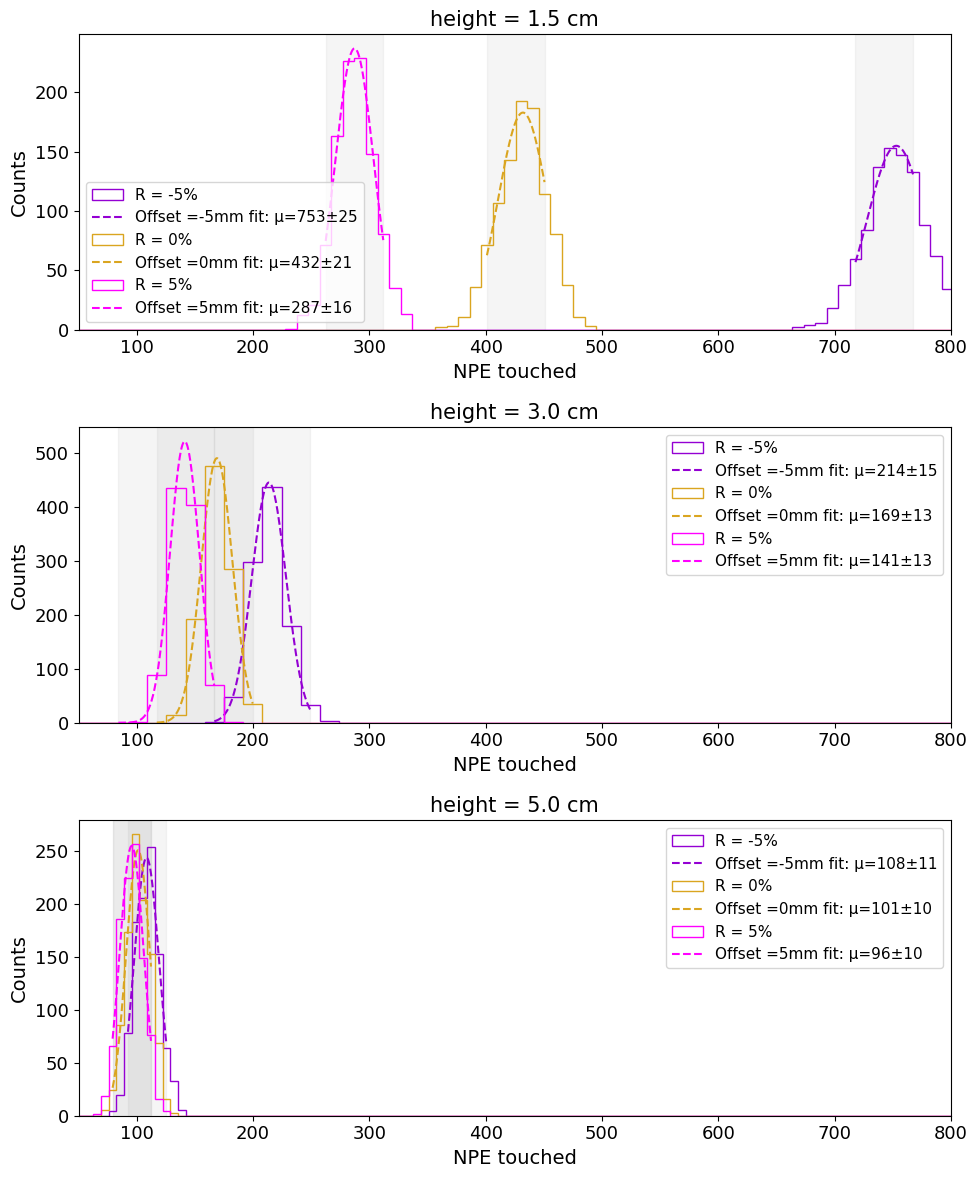

In [38]:
# One subplot per source height; all reflectivities overlaid on each
fig, axes = plt.subplots(len(HEIGHTS), 1, figsize=(10, 4 * len(HEIGHTS)), sharex=False)
height_ax = dict(zip(HEIGHTS, axes))

for (folder, height), sim in sorted(sims.items()):
    ax  = height_ax[height]
    cfg = HIST_CFG[height]
    counts, edges, _ = ax.hist(sim.npe, bins=cfg['nbins'], range=(HIST_LOWER, HIST_UPPER),
                                histtype='step', color=REF_COLORS[sim.ref_pct],
                                label=f'R = {sim.ref_pct}%')
    sim.bin_counts, sim.bin_edges = counts, edges
    sim.bin_centers = 0.5 * (edges[1:] + edges[:-1])

    # Gaussian fit around histogram peak
    ip     = np.argmax(counts)
    lo, hi = max(0, ip - FIT_HALF_BINS), min(len(counts), ip + FIT_HALF_BINS)
    sim.fit = fit_histogram_gaussian(sim.bin_centers[lo:hi], counts[lo:hi])
    mu, sig = sim.fit.values['mean'], sim.fit.values['sigma']

    x_fit = np.linspace(sim.bin_centers[lo], sim.bin_centers[hi - 1], 200)
    ax.plot(x_fit, gaussian(x_fit, sim.fit.values['amplitude'], mu, sig),
            color=REF_COLORS[sim.ref_pct], lw=1.5, ls='--',
            label=f'Offset ={sim.ref_pct}mm fit: μ={mu:.0f}±{sig:.0f}')
    ax.axvspan(sim.bin_centers[lo], sim.bin_centers[hi - 1], alpha=0.08, color='gray')

for h, ax in height_ax.items():
    ax.set_title(f'height = {h} cm')
    ax.set_xlabel('NPE touched'); ax.set_ylabel('Counts')
    ax.legend()
    
    # set xlim dynamically from max bin entry across all reflectivities for this height
    max_count = max(sims[(folder, h)].bin_counts.max() for folder in H_MAP)
    ax.set_xlim(50, 800)

plt.tight_layout(); plt.show()

[1.0, 1.0, 1.0]
offset=0 mm: average frac = 1.000
[1.7430218011967007, 1.2648142043159734, 1.0717809052609617]
offset=-5 mm: average frac = 1.360
[0.6649639603185926, 0.8363329776514813, 0.9455896550772148]
offset=5 mm: average frac = 0.816


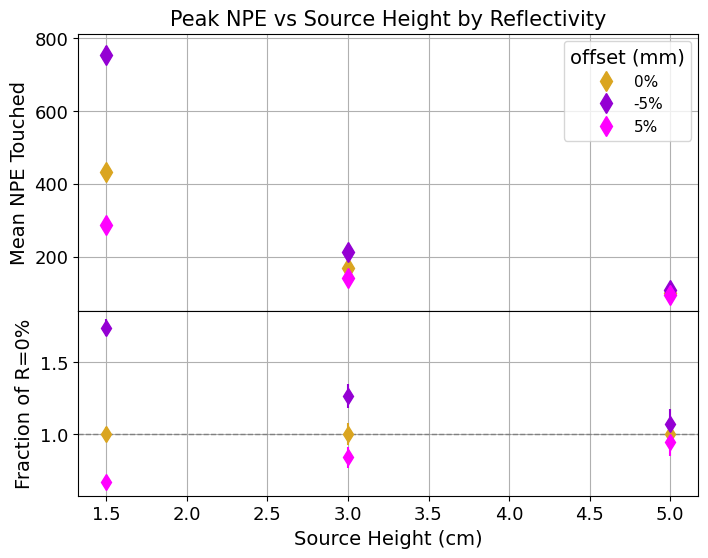

In [45]:
# Summary: Gaussian peak (mean +/- sigma) vs source height, by reflectivity
REF_NORM = 0   # reflectivity % to normalize against in residual panel

fig, (ax_top, ax_bot) = plt.subplots(2, 1, figsize=(8, 6), sharex=True,
                                      gridspec_kw={'height_ratios': [3, 2]})

ref_norm_folder = next(f for f, r in H_MAP.items() if r == REF_NORM)
norm_means = [sims[(ref_norm_folder, h)].fit.values['mean'] for h in HEIGHTS]

for folder, ref_pct in H_MAP.items():
    row    = [sims[(folder, h)] for h in HEIGHTS]
    means  = [s.fit.values['mean']  for s in row]
    sigmas = [s.fit.values['sigma'] for s in row]

    ax_top.errorbar(HEIGHTS, means, yerr=sigmas, marker='d', markersize=10,
                    linestyle='None', color=REF_COLORS[ref_pct], label=f'{ref_pct}%')

    frac       = [m / n for m, n in zip(means, norm_means)]
    frac_err   = [s / n for s, n in zip(sigmas, norm_means)]
    ax_bot.errorbar(HEIGHTS, frac, yerr=frac_err, marker='d', markersize=8,
                    linestyle='None', color=REF_COLORS[ref_pct], label=f'Offset = {ref_pct}%')
    print(frac)
    print(f"offset={ref_pct} mm: average frac = {np.mean(frac):0.3f}")

ax_top.set_ylabel('Mean NPE Touched')
ax_top.set_title('Peak NPE vs Source Height by Reflectivity')
ax_top.legend(title = "offset (mm)")

ax_bot.axhline(1.0, color='gray', lw=1, ls='--')
ax_bot.set_xlabel('Source Height (cm)')
ax_bot.set_ylabel(f'Fraction of R={REF_NORM}%')

# plt.tight_layout();

ax_top.grid()
ax_bot.grid()

plt.subplots_adjust(hspace=0.0) 
plt.show()

In [44]:
sysOptics = [0.11, 0.13] ## increase LY by this much

sysNCA = [0, 0.22-0.17] ## make LY lower by this fraction (if actually 0.22 we dont correct enough)

lyvis = [2.88, 2.39, 2.93]

lowError = np.abs(lyvis[0] - lyvis[1])
highError = np.abs(lyvis[2] - lyvis[0])

print(f"ly vis = {lyvis[0]} +{highError:0.2f} -{lowError:0.2f}")

fullLowError = lyvis[0] * np.sqrt((lowError/lyvis[0])**2 + sysOptics[0]**2 + sysNCA[0]**2)
fullHighError = lyvis[0] * np.sqrt((highError/lyvis[0])**2 + sysOptics[1]**2 + sysNCA[1]**2)

print(f"full low error = {fullLowError:0.2f}")
print(f"full high error = {fullHighError:0.2f}")

ly vis = 2.88 +0.05 -0.49
full low error = 0.58
full high error = 0.40


0.024375